In [34]:
import pandas as pd 
import numpy as np 

In [35]:
data = pd.read_csv('Melbourne_Housing.csv')

In [36]:
missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})  

,count,Percentage
Distance,1,0.003688
Postcode,1,0.003688
Bedroom,6436,23.736815
Bathroom,6442,23.758944
Car,6817,25.141993
Landsize,9241,34.082024
BuildingArea,16571,61.116029
YearBuilt,15129,55.797743


* BuildingArea and YearBuilt columns have the highest percentage of missing values.
* Distance and Postcode have the least number of missing values
* Bedroom,Bathroom, and Car have almost equal percentage of missing values


Missing value treatment for Distance column

In [8]:
# extracting all the informatio of other variables where Distance is null
data[data['Distance'].isnull()==True]

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Propertycount,Price
9594,Fawkner Lot,3,h,Brad,06-01-2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Northern Metropolitan,962,616000


In [9]:
data.loc[data['Suburb']=='Fawkner Lot']

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Propertycount,Price
9594,Fawkner Lot,3,h,Brad,06-01-2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Northern Metropolitan,962,616000


* We see that there is only one data entry for the Fawkner Lot and in this case it is possible that data for this suburb was not collected.

so drop this row

In [10]:
# adding the index value of the row in data.drop() function 
data = data.drop(9594).reset_index(drop=True)

In [ ]:
missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})

,count,Percentage
Bedroom,6435,23.734002
Bathroom,6441,23.756132
Car,6816,25.139232
Landsize,9240,34.079593
BuildingArea,16570,61.114594
YearBuilt,15128,55.796113


In [12]:
# extracting all the information of other variable where Bedroom is null
data.loc[data['Bedroom'].isnull()==True]

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Propertycount,Price
8,Altona North,4,h,hockingstuart,03-09-2016,11.1,3025.0,NaN,NaN,NaN,NaN,missing,NaN,Western Metropolitan,5132,857500
12,Ashburton,2,h,Marshall,03-09-2016,11.0,3147.0,NaN,NaN,NaN,NaN,inf,NaN,Southern Metropolitan,3052,1820000
14,Avondale Heights,4,h,Jellis,03-09-2016,10.5,3034.0,NaN,NaN,NaN,NaN,missing,NaN,Western Metropolitan,4502,1310000
25,Balwyn North,4,u,hockingstuart,03-09-2016,9.2,3104.0,NaN,NaN,NaN,NaN,missing,NaN,Southern Metropolitan,7809,1450000
26,Balwyn North,2,h,Fletchers,03-09-2016,9.2,3104.0,NaN,NaN,NaN,NaN,missing,NaN,Southern Metropolitan,7809,1305000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27099,Footscray,2,u,McGrath,30-09-2017,5.1,3011.0,NaN,NaN,NaN,NaN,NaN,NaN,Western Metropolitan,7570,455500
27100,Forest Hill,2,h,Fletchers,30-09-2017,15.4,3131.0,NaN,NaN,NaN,NaN,NaN,NaN,Eastern Metropolitan,4385,762000
27101,Glen Waverley,3,u,Ray,30-09-2017,16.7,3150.0,NaN,NaN,NaN,NaN,NaN,NaN,Eastern Metropolitan,15321,1100000
27104,Kingsbury,2,t,RW,30-09-2017,12.1,3083.0,NaN,NaN,NaN,NaN,NaN,NaN,Northern Metropolitan,1414,512000


* it looks like wherever Bedroom is null the data points in other columns are also missing. Let's check this

In [13]:
data.loc[data['Bedroom'].isnull()==True,'Bathroom'].value_counts(dropna=False)

Bathroom
NaN    6435
Name: count, dtype: int64

In [17]:
data.loc[data['Bedroom'].isnull()==True,'Car'].value_counts(dropna=False)

Car
NaN    6435
Name: count, dtype: int64

* dropna = False cozz default values ignores missing

In [18]:
data.loc[data['Bedroom'].isnull()==True,'Landsize'].value_counts(dropna=False)

Landsize
NaN      6429
594.0       1
446.0       1
338.0       1
250.0       1
549.0       1
239.0       1
Name: count, dtype: int64

In [19]:
data.loc[data['Bedroom'].isnull()==True,'BuildingArea'].value_counts(dropna=False)

BuildingArea
NaN        6430
missing       4
inf           1
Name: count, dtype: int64

* There seems to be a strong pattern in missing values,as wherever Bedroom column has missing data all other above column also have missing values
* Let's see if the missing data has some pattern in suburbs, and regions of properties

In [22]:
data.loc[data['Bedroom'].isnull()==True,'Suburb'].value_counts(dropna
=False)

Suburb
Reservoir         236
Bentleigh East    144
St Kilda          117
Glenroy           116
Richmond          111
                 ... 
Scoresby            1
Warranwood          1
croydon             1
viewbank            1
Plenty              1
Name: count, Length: 307, dtype: int64

In [23]:
# to find the total number of unique values in a suburb
data['Suburb'].nunique()

344

* Across 344 suburb has missing value

In [24]:
data.loc[data['Bedroom'].isnull()==True,'Regionname'].value_counts(dropna=False)

Regionname
Southern Metropolitan         2201
Northern Metropolitan         1915
Western Metropolitan          1215
Eastern Metropolitan           728
South-Eastern Metropolitan     318
Eastern Victoria                26
Northern Victoria               25
Western Victoria                 7
Name: count, dtype: int64

* similar to suburb Regionname has no pattern

Missing value treatment for Bedroom,Bathroom,and Car columns

In [37]:
# checking the average number of bedrooms,bathrooms, and car parking spaces in a region
data.groupby(['Regionname','Type'])[['Bedroom','Bathroom','Car']].mean()

Bedroom  Bathroom       Car
Regionname                 Type                              
Eastern Metropolitan       h     3.551948  1.806961  1.946176
                           t     3.032051  1.852564  1.673077
                           u     2.357143  1.263393  1.290179
Eastern Victoria           h     3.559701  1.880597  2.098485
                           u     2.666667  1.000000  1.333333
Northern Metropolitan      h     3.106336  1.467878  1.684897
                           t     2.567198  1.619590  1.362187
                           u     1.878049  1.160127  1.092652
Northern Victoria          h     3.496403  1.892086  2.145985
                           u     3.000000  2.000000  2.000000
South-Eastern Metropolitan h     3.475924  1.713326  2.093574
                           t     2.886792  1.849057  1.679245
                           u     2.260274  1.205479  1.342466
Southern Metropolitan      h     3.383430  1.840283  1.882764
                           t     3.024014  2.012027  1.779690
                           u     1.938541  1.190805  1.134870
Western Metropolitan       h     3.244238  1.576159  1.906782
                           t     2.879747  1.850794  1.538217
                           u     2.106339  1.192229  1.143737
Western Victoria           h     3.379310  1.448276  2.060241

In [38]:
# imputing missing values in Bedroom column
data["Bedroom"] = data["Bedroom"].fillna(value=data.groupby(["Regionname","Type"])["Bedroom"].transform("mean"))

In [39]:
# imputing missing values in Bedroom column 
data["Bathroom"] = data["Bathroom"].fillna(value=data.groupby(["Regionname","Type"])["Bathroom"].transform("mean"))

In [40]:
data["Car"]=data["Car"].fillna(value=data.groupby(["Regionname","Type"])["Car"].transform("mean"))

In [41]:
missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})

,count,Percentage
Distance,1,0.003688
Postcode,1,0.003688
Landsize,9241,34.082024
BuildingArea,16571,61.116029
YearBuilt,15129,55.797743


below col has descrite values

In [42]:
data["Bathroom"] = data["Bathroom"].astype(int)
data["Bedroom"] = data["Bedroom"].astype(int)
data["Car"] = data["Car"].astype(int)

In [43]:
data['Total_Space_New'] = data['Rooms']+data['Bedroom']+data['Bathroom']+data['Car']
data['Total_Space_New']=data['Total_Space_New'].astype(int)

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

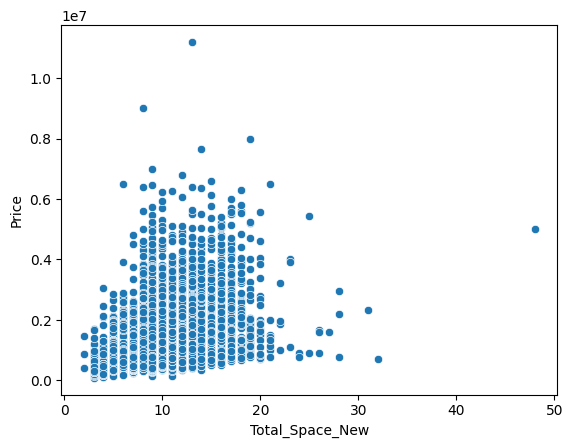

In [45]:
sns.scatterplot(data=data,x='Total_Space_New',y='Price')
plt.show()

Missing value Treatment for Landsize

Use Mean when:

The data is normally distributed (bell-shaped)

There are no significant outliers

Use Median when:

The data is skewed.
There are outliers


<Axes: xlabel='Landsize', ylabel='Count'>

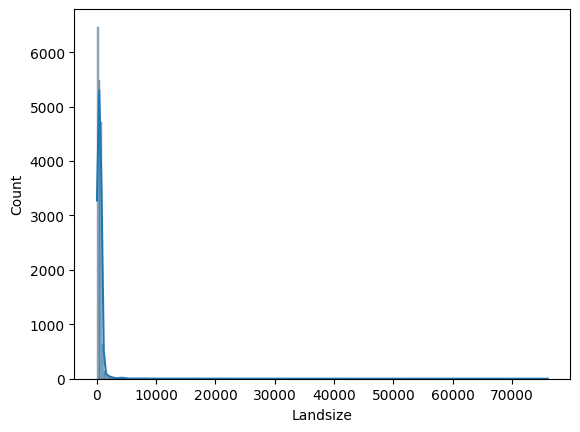

In [46]:
sns.histplot(data['Landsize'],kde=True)

We'll use median data is skewed here

In [47]:
data["Landsize"]=data["Landsize"].fillna(value=data.groupby(["Regionname","Type"])["Landsize"].transform('median'))

In [48]:
missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})

,count,Percentage
Distance,1,0.003688
Postcode,1,0.003688
BuildingArea,16571,61.116029
YearBuilt,15129,55.797743


Missing value treatment for BuildingArea, Yearbuilt

In [49]:
new_data = data[data["BuildingArea"].notnull()]
new_data.head()

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Propertycount,Price,Total_Space_New
0,Airport West,3,t,Nelson,03-09-2016,13.5,3042.0,3,2,1,303.0,225,2016.0,Western Metropolitan,3464,840000,9
1,Albert Park,2,h,hockingstuart,03-09-2016,3.3,3206.0,2,1,0,120.0,82,1900.0,Southern Metropolitan,3280,1275000,5
2,Albert Park,2,h,Thomson,03-09-2016,3.3,3206.0,2,1,0,159.0,inf,NaN,Southern Metropolitan,3280,1455000,5
3,Alphington,4,h,Brace,03-09-2016,6.4,3078.0,3,2,4,853.0,263,1930.0,Northern Metropolitan,2211,2000000,13
4,Alphington,3,h,Jellis,03-09-2016,6.4,3078.0,3,2,2,208.0,inf,2013.0,Northern Metropolitan,2211,1110000,10


In [53]:
data.drop(['BuildingArea', 'YearBuilt'], axis=1,)

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,Regionname,Propertycount,Price,Total_Space_New
0,Airport West,3,t,Nelson,03-09-2016,13.5,3042.0,3,2,1,303.0,Western Metropolitan,3464,840000,9
1,Albert Park,2,h,hockingstuart,03-09-2016,3.3,3206.0,2,1,0,120.0,Southern Metropolitan,3280,1275000,5
2,Albert Park,2,h,Thomson,03-09-2016,3.3,3206.0,2,1,0,159.0,Southern Metropolitan,3280,1455000,5
3,Alphington,4,h,Brace,03-09-2016,6.4,3078.0,3,2,4,853.0,Northern Metropolitan,2211,2000000,13
4,Alphington,3,h,Jellis,03-09-2016,6.4,3078.0,3,2,2,208.0,Northern Metropolitan,2211,1110000,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27109,Noble Park,3,h,C21,30-09-2017,22.7,3174.0,3,1,6,569.0,South-Eastern Metropolitan,11806,627500,13
27110,Reservoir,3,u,RW,30-09-2017,12.0,3073.0,3,1,1,50.0,Northern Metropolitan,21650,475000,8
27111,Roxburgh Park,4,h,Raine,30-09-2017,20.6,3064.0,4,2,2,482.0,Northern Metropolitan,5833,591000,12
27112,Springvale South,3,h,Harcourts,30-09-2017,22.2,3172.0,3,2,1,544.0,South-Eastern Metropolitan,4054,780500,9


In [54]:
# saving the dataset with all the missing values treated
data1 = data.to_csv('after_missing_handling.csv')

In [ ]:
missing = data.isnull().sum()

pd.DataFrame({
    'count': missing[missing > 0],
    'Percentage': (missing[missing > 0] / len(data)) * 100
})

,count,Percentage
Distance,1,0.003688
Postcode,1,0.003688
BuildingArea,16571,61.116029
YearBuilt,15129,55.797743
